In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (accuracy_score, precision_score, 
                             recall_score, f1_score, 
                             confusion_matrix, classification_report)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/processed/preprocessed_data.csv')

print("Data loaded")
print("Shape:", df.shape)


Data loaded
Shape: (938599, 15)


In [3]:
# Prepare Features and Target
# Load selected features
with open('../data/processed/selected_features.json', 'r') as f:
    selected_features = json.load(f)

print("Selected features:", selected_features)

# Case 1: PHA Classification
X = df[selected_features]
y = df['pha_encoded']

print("\nX shape:", X.shape)
print("y distribution:")
print(y.value_counts())


Selected features: ['n_log', 'w', 'ma', 'e_log', 'a_log', 'q_log']

X shape: (938599, 6)
y distribution:
pha_encoded
0    936533
1      2066
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("\nTrain target:")
print(y_train.value_counts())

Train: (750879, 6)
Test: (187720, 6)

Train target:
pha_encoded
0    749226
1      1653
Name: count, dtype: int64


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done")

Scaling done


In [6]:
# Handle Imbalance — SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", pd.Series(y_train_smote).value_counts().to_dict())


Before SMOTE: {0: 749226, 1: 1653}
After SMOTE: {0: 749226, 1: 749226}


In [7]:
#Train Model 1 — Logistic Regression
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_smote, y_train_smote)

y_pred_lr = lr.predict(X_test_scaled)

print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1: {f1_score(y_test, y_pred_lr):.4f}")

Logistic Regression Results:
Accuracy: 0.9794
Precision: 0.0965
Recall: 1.0000
F1: 0.1761


In [8]:
#Train Model 2 — Random Forest


# Train Model 2 — Random Forest (smaller version)
rf = RandomForestClassifier(
    n_estimators=50,       # 100 → 50
    max_depth=15,          # Add depth limit
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_smote, y_train_smote)

y_pred_rf = rf.predict(X_test_scaled)

print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1: {f1_score(y_test, y_pred_rf):.4f}")

Random Forest Results:
Accuracy: 0.9867
Precision: 0.1379
Recall: 0.9613
F1: 0.2412


In [9]:
#Train Model 3 — XGBoost
xgb = XGBClassifier(n_estimators=100, random_state=42, 
                    use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train_smote, y_train_smote)

y_pred_xgb = xgb.predict(X_test_scaled)

print("XGBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1: {f1_score(y_test, y_pred_xgb):.4f}")


e:\astroid\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:01:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Results:
Accuracy: 0.9890
Precision: 0.1549
Recall: 0.9007
F1: 0.2643


In [10]:

results = {
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1': f1_score(y_test, y_pred_lr)
    },
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1': f1_score(y_test, y_pred_rf)
    },
    'XGBoost': {
        'Accuracy': accuracy_score(y_test, y_pred_xgb),
        'Precision': precision_score(y_test, y_pred_xgb),
        'Recall': recall_score(y_test, y_pred_xgb),
        'F1': f1_score(y_test, y_pred_xgb)
    }
}

results_df = pd.DataFrame(results).T
print(results_df)

                     Accuracy  Precision    Recall        F1
Logistic Regression  0.979411   0.096540  1.000000  0.176082
Random Forest        0.986693   0.137895  0.961259  0.241191
XGBoost              0.988968   0.154871  0.900726  0.264298


In [11]:
# F1 highest → best model (imbalanced data-க்கு)
best_model_name = results_df['F1'].idxmax()
print("Best Model:", best_model_name)
print("Best F1:", results_df.loc[best_model_name, 'F1'])

Best Model: XGBoost
Best F1: 0.2642984014209592


In [12]:
best_model = rf
best_model_name = "Random Forest"
print("Best model set:", best_model_name)

Best model set: Random Forest


In [13]:
# Check if variables exist
try:
    print("best_model:", best_model)
    print("scaler:", scaler)
except NameError as e:
    print("Error:", e)

best_model: RandomForestClassifier(class_weight='balanced', max_depth=15, n_estimators=50,
                       n_jobs=-1, random_state=42)
scaler: StandardScaler()


In [14]:
import joblib
import os

# Create models folder
os.makedirs('../models', exist_ok=True)

# Save best model and scaler
joblib.dump(best_model, '../models/pha_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

# Verify
print("Model saved!")
print("Files in models folder:")
for f in os.listdir('../models'):
    print(" -", f)

Model saved!
Files in models folder:
 - diameter_model.pkl
 - kmeans_model.pkl
 - pha_model.pkl
 - scaler.pkl
 - scaler_cluster.pkl
 - scaler_reg.pkl
 - shap_explainer.pkl
 - shap_explainer_reg.pkl


In [15]:
import shap

# Use 1000 samples only (fast)
X_sample = X_test_scaled[:1000]

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_sample)

print("SHAP values computed")
print("Shape:", np.array(shap_values).shape)

e:\astroid\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values computed
Shape: (1000, 6, 2)


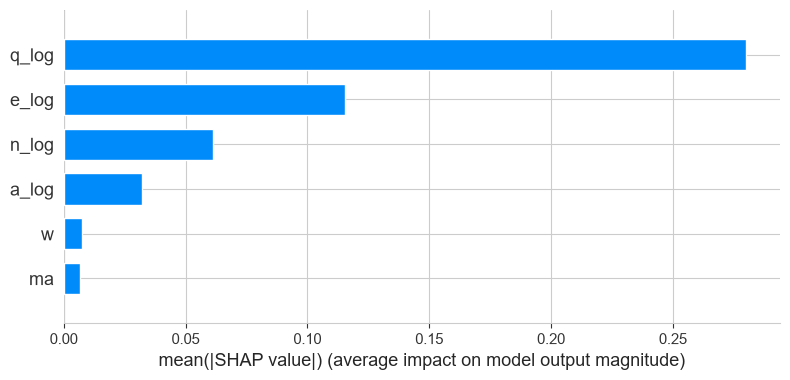

In [16]:
# SHAP Bar Plot - for PHA class (class 1)
shap.summary_plot(shap_values[:, :, 1], X_sample, 
                  feature_names=selected_features, 
                  plot_type='bar')

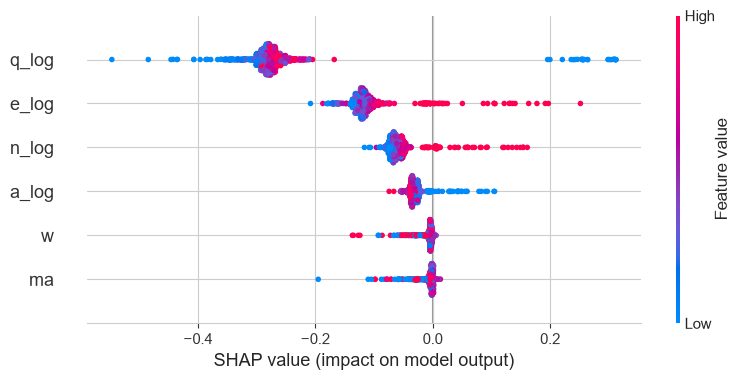

In [17]:
# SHAP Dot Plot - for PHA class
shap.summary_plot(shap_values[:, :, 1], X_sample, 
                  feature_names=selected_features)

In [18]:
import pickle

with open('../models/shap_explainer.pkl', 'wb') as f:
    pickle.dump(explainer, f)

print("SHAP explainer saved")

SHAP explainer saved


In [19]:
import os
for f in os.listdir('../models'):
    size = os.path.getsize(f'../models/{f}') / (1024*1024)
    print(f"{f}: {size:.2f} MB")

diameter_model.pkl: 0.00 MB
kmeans_model.pkl: 0.02 MB
pha_model.pkl: 14.69 MB
scaler.pkl: 0.00 MB
scaler_cluster.pkl: 0.00 MB
scaler_reg.pkl: 0.00 MB
shap_explainer.pkl: 5.34 MB
shap_explainer_reg.pkl: 0.01 MB
